In [2]:
from datascience import *
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

Standard_deviation / sqrt( random sample size ) = standard deviation of the sample distribution

- the standard deviation is the standard deviation of what you are pulling samples from

### From a random sample, construct a 95% confidence interval for the ages of the mothers in the population

## Use Bootstrapping

In [5]:
births = Table.read_table('baby.csv')
births.show(5)

Birth Weight,Gestational Days,Maternal Age,Maternal Height,Maternal Pregnancy Weight,Maternal Smoker
120,284,27,62,100,False
113,282,33,64,135,False
128,279,28,64,115,True
108,282,23,67,125,True
136,286,25,62,93,False


In [9]:
def one_bootstrap_mean():
    resample = births.sample()
    return np.average(resample.column('Maternal Age'))


In [20]:
# generate means for 3000 bootstrap samples
num_repititions = 3000
bstrap_means = make_array()
for i in np.arange(num_repititions):
    bstrap_means = np.append(bstrap_means, one_bootstrap_mean())

In [21]:
# get the endpoints of the 95% confidence interval
left = percentile(2.5, bstrap_means)
right = percentile(97.5, bstrap_means)

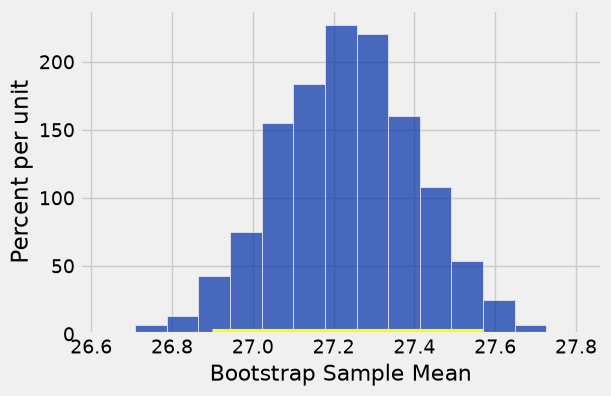

In [26]:
resampled_means = Table().with_columns('Bootstrap Sample Mean', bstrap_means)
resampled_means.hist(bins=15)
plt.plot([left, right], [0, 0], color='yellow', lw=8)

In [27]:
left, right

(26.897785349233391, 27.570698466780239)

## Using CLT (since we are using averages)

In [39]:
sample_ages = births.column('Maternal Age')
sample_size = len(sample_ages)
sample_average = np.average(sample_ages)
sample_SD = np.std(sample_ages)
sample_size, sample_averages, sample_SD

(1174, 27.228279386712096, 5.8153604041908968)

In [40]:
# we do not know what the pupulation SD, instead use the sample sd

estimated_SD_of_sample_average = sample_SD / (sample_size ** .5)
estimated_SD_of_sample_average

0.16972373742299796

In [41]:
# Approximate 95% confidence interval for population mean
sample_average - 2 * estimated_SD_of_sample_average, sample_average + 2 * estimated_SD_of_sample_average

(26.888831911866099, 27.567726861558093)

## Choosing a sample size given an interval width

- proportions are averages
- as sample size increases, margin of error decreases, as long as you set your margin of error before start
  

In [46]:
# population of size 10
number_of_ones = 2
zero_one_population = np.append(np.ones(number_of_ones), np.zeros(10-number_of_ones))

print('Standard Deviation:', np.round(np.std(zero_one_population), 2))
zero_one_population

Standard Deviation: 0.4


array([ 1.,  1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.])

In [64]:
def  sd_zero_one_population(number_of_ones):
    zero_one_population = np.append(np.ones(number_of_ones), np.zeros(100-number_of_ones))
    return np.std(zero_one_population)

In [65]:
possible_ones = np.arange(101)
zero_one_pop = Table().with_columns('Number of ones', possible_ones, 
                                    'Proportion of ones', possible_ones/10
                                   )
zero_one_pop.show(11)

Number of ones,Proportion of ones
0,0
1,0.1
2,0.2
3,0.3
4,0.4
5,0.5
6,0.6
7,0.7
8,0.8
9,0.9


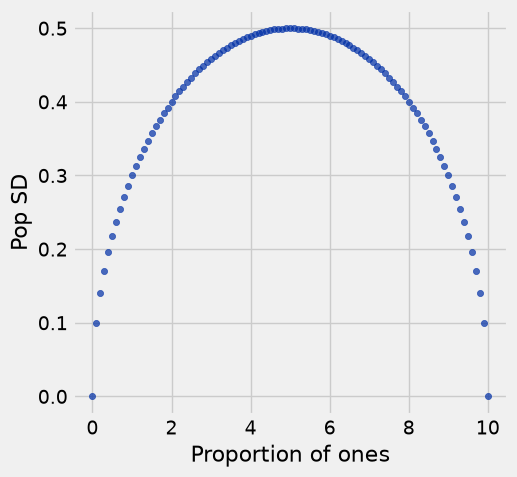

In [70]:
sds = zero_one_pop.apply(sd_zero_one_population, 'Number of ones')
zero_one_pop = zero_one_pop.with_column('Pop SD', sds)
zero_one_pop.scatter('Proportion of ones', 'Pop SD')

In [75]:
print(( 4 * 0.5 / .01) **2)

40000.0


In [87]:
print(( 4 * 0.5 / .0631) **2)

1004.6187346324726
